In [ ]:

import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


GPU Available: True
GPU Name: Tesla T4


In [ ]:

%pip install -q transformers peft datasets accelerate bitsandbytes scikit-learn pandas matplotlib seaborn


In [ ]:

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("All libraries imported successfully!")
print("GPU:", torch.cuda.get_device_name(0))


All libraries imported successfully!
GPU: Tesla T4


In [ ]:

dataset = load_dataset("PolyAI/banking77")

train_data = pd.DataFrame(dataset["train"])
test_data = pd.DataFrame(dataset["test"])

print("Training examples:", len(train_data))
print("Testing examples:", len(test_data))

print("\nSample data:")
print(train_data.head())


README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

Training examples: 10003
Testing examples: 3080

Sample data:
                                                text  label
0                     I am still waiting on my card?     11
1  What can I do if my card still hasn't arrived ...     11
2  I have been waiting over a week. Is the card s...     11
3  Can I track my card while it is in the process...     11
4  How do I know if I will get my card, or if it ...     11


In [ ]:

labels = dataset["train"].features["label"].names

print("Total categories:", len(labels))
print("\nAll original categories:\n")

for i, name in enumerate(labels):
    print(i, ":", name)


Total categories: 77

All original categories:

0 : activate_my_card
1 : age_limit
2 : apple_pay_or_google_pay
3 : atm_support
4 : automatic_top_up
5 : balance_not_updated_after_bank_transfer
6 : balance_not_updated_after_cheque_or_cash_deposit
7 : beneficiary_not_allowed
8 : cancel_transfer
9 : card_about_to_expire
10 : card_acceptance
11 : card_arrival
12 : card_delivery_estimate
13 : card_linking
14 : card_not_working
15 : card_payment_fee_charged
16 : card_payment_not_recognised
17 : card_payment_wrong_exchange_rate
18 : card_swallowed
19 : cash_withdrawal_charge
20 : cash_withdrawal_not_recognised
21 : change_pin
22 : compromised_card
23 : contactless_not_working
24 : country_support
25 : declined_card_payment
26 : declined_cash_withdrawal
27 : declined_transfer
28 : direct_debit_payment_not_recognised
29 : disposable_card_limits
30 : edit_personal_details
31 : exchange_charge
32 : exchange_rate
33 : exchange_via_app
34 : extra_charge_on_statement
35 : failed_transfer
36 : fiat_cu

Category distribution:

activate_my_card : 159
age_limit : 110
apple_pay_or_google_pay : 126
atm_support : 87
automatic_top_up : 127
balance_not_updated_after_bank_transfer : 171
balance_not_updated_after_cheque_or_cash_deposit : 181
beneficiary_not_allowed : 156
cancel_transfer : 157
card_about_to_expire : 129
card_acceptance : 59
card_arrival : 153
card_delivery_estimate : 112
card_linking : 139
card_not_working : 112
card_payment_fee_charged : 187
card_payment_not_recognised : 168
card_payment_wrong_exchange_rate : 167
card_swallowed : 61
cash_withdrawal_charge : 177
cash_withdrawal_not_recognised : 160
change_pin : 122
compromised_card : 86
contactless_not_working : 35
country_support : 129
declined_card_payment : 153
declined_cash_withdrawal : 173
declined_transfer : 133
direct_debit_payment_not_recognised : 182
disposable_card_limits : 121
edit_personal_details : 121
exchange_charge : 121
exchange_rate : 112
exchange_via_app : 118
extra_charge_on_statement : 166
failed_transfer :

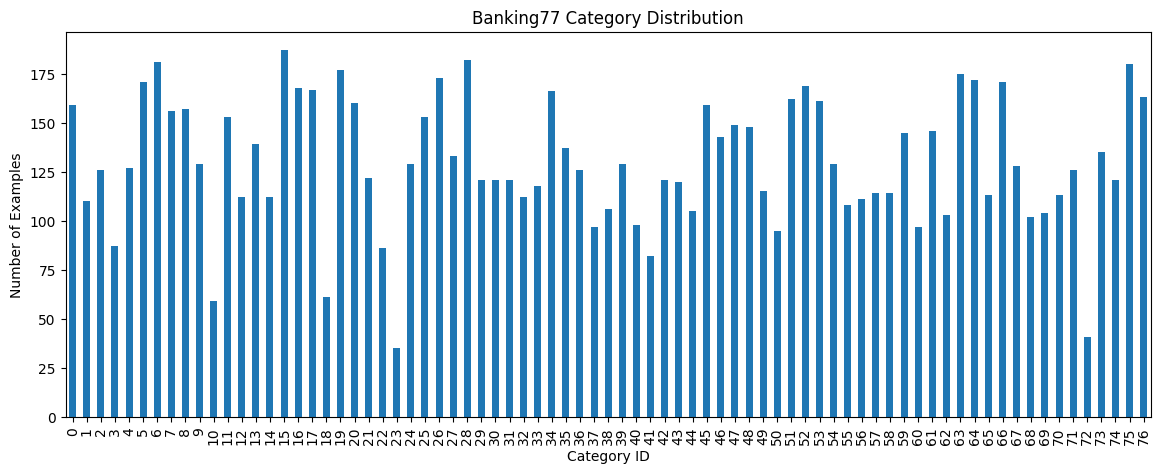

In [ ]:

print("Category distribution:\n")

counts = train_data["label"].value_counts().sort_index()

for i, count in counts.items():
    print(labels[i], ":", count)

plt.figure(figsize=(14, 5))
counts.plot(kind="bar")
plt.title("Banking77 Category Distribution")
plt.xlabel("Category ID")
plt.ylabel("Number of Examples")
plt.show()


In [ ]:

category_map = {
    "activate_my_card": "card_services",
    "age_limit": "account_security",
    "apple_pay_or_google_pay": "card_services",
    "atm_support": "cash_withdrawals",
    "automatic_top_up": "topups_balances",
    "balance_not_updated_after_bank_transfer": "topups_balances",
    "balance_not_updated_after_cheque_or_cash_deposit": "topups_balances",
    "beneficiary_not_allowed": "payments_transfers",
    "cancel_transfer": "payments_transfers",
    "card_about_to_expire": "card_services",
    "card_acceptance": "card_services",
    "card_arrival": "card_services",
    "card_delivery_estimate": "card_services",
    "card_linking": "card_services",
    "card_not_working": "card_services",
    "card_payment_fee_charged": "fees_refunds_exchange",
    "card_payment_not_recognised": "fees_refunds_exchange",
    "card_payment_wrong_exchange_rate": "fees_refunds_exchange",
    "card_swallowed": "card_services",
    "cash_withdrawal_charge": "cash_withdrawals",
    "cash_withdrawal_not_recognised": "cash_withdrawals",
    "change_pin": "card_services",
    "compromised_card": "card_services",
    "contactless_not_working": "card_services",
    "country_support": "account_security",
    "declined_card_payment": "card_services",
    "declined_cash_withdrawal": "cash_withdrawals",
    "declined_transfer": "payments_transfers",
    "direct_debit_payment_not_recognised": "fees_refunds_exchange",
    "disposable_card_limits": "card_services",
    "edit_personal_details": "account_security",
    "exchange_charge": "fees_refunds_exchange",
    "exchange_rate": "fees_refunds_exchange",
    "exchange_via_app": "fees_refunds_exchange",
    "extra_charge_on_statement": "fees_refunds_exchange",
    "failed_transfer": "payments_transfers",
    "fiat_currency_support": "account_security",
    "get_disposable_virtual_card": "card_services",
    "get_physical_card": "card_services",
    "getting_spare_card": "card_services",
    "getting_virtual_card": "card_services",
    "lost_or_stolen_card": "card_services",
    "lost_or_stolen_phone": "account_security",
    "order_physical_card": "card_services",
    "passcode_forgotten": "account_security",
    "pending_card_payment": "fees_refunds_exchange",
    "pending_cash_withdrawal": "cash_withdrawals",
    "pending_top_up": "topups_balances",
    "pending_transfer": "payments_transfers",
    "pin_blocked": "card_services",
    "receiving_money": "payments_transfers",
    "Refund_not_showing_up": "fees_refunds_exchange",
    "request_refund": "fees_refunds_exchange",
    "reverted_card_payment?": "fees_refunds_exchange",
    "supported_cards_and_currencies": "card_services",
    "terminate_account": "account_security",
    "top_up_by_bank_transfer_charge": "fees_refunds_exchange",
    "top_up_by_card_charge": "fees_refunds_exchange",
    "top_up_by_cash_or_cheque": "topups_balances",
    "top_up_failed": "topups_balances",
    "top_up_limits": "topups_balances",
    "top_up_reverted": "topups_balances",
    "topping_up_by_card": "topups_balances",
    "transaction_charged_twice": "fees_refunds_exchange",
    "transfer_fee_charged": "fees_refunds_exchange",
    "transfer_into_account": "payments_transfers",
    "transfer_not_received_by_recipient": "payments_transfers",
    "transfer_timing": "payments_transfers",
    "unable_to_verify_identity": "account_security",
    "verify_my_identity": "account_security",
    "verify_source_of_funds": "account_security",
    "verify_top_up": "topups_balances",
    "virtual_card_not_working": "card_services",
    "visa_or_mastercard": "card_services",
    "why_verify_identity": "account_security",
    "wrong_amount_of_cash_received": "cash_withdrawals",
    "wrong_exchange_rate_for_cash_withdrawal": "cash_withdrawals"
}

print("Total mapped labels:", len(category_map))
print("Total original labels:", len(labels))

missing = set(labels) - set(category_map.keys())
extra = set(category_map.keys()) - set(labels)

print("Missing labels:", missing)
print("Extra labels:", extra)

assert len(category_map) == 77
assert len(missing) == 0
assert len(extra) == 0

print("All labels mapped successfully!")


Total mapped labels: 77
Total original labels: 77
Missing labels: set()
Extra labels: set()
All labels mapped successfully!


In [ ]:

train_data["intent"] = train_data["label"].apply(
    lambda x: labels[x]
)

test_data["intent"] = test_data["label"].apply(
    lambda x: labels[x]
)

train_data["category"] = train_data["intent"].map(category_map)
test_data["category"] = test_data["intent"].map(category_map)

print(train_data[["text", "intent", "category"]].head(10))

print("\nNew category distribution:")
print(train_data["category"].value_counts())


                                                text        intent  \
0                     I am still waiting on my card?  card_arrival   
1  What can I do if my card still hasn't arrived ...  card_arrival   
2  I have been waiting over a week. Is the card s...  card_arrival   
3  Can I track my card while it is in the process...  card_arrival   
4  How do I know if I will get my card, or if it ...  card_arrival   
5                  When did you send me my new card?  card_arrival   
6       Do you have info about the card on delivery?  card_arrival   
7  What do I do if I still have not received my n...  card_arrival   
8       Does the package with my card have tracking?  card_arrival   
9          I ordered my card but it still isn't here  card_arrival   

        category  
0  card_services  
1  card_services  
2  card_services  
3  card_services  
4  card_services  
5  card_services  
6  card_services  
7  card_services  
8  card_services  
9  card_services  

New category distri

In [ ]:

print("Missing values in training:")
print(train_data[["text", "category"]].isnull().sum())

print("\nMissing values in testing:")
print(test_data[["text", "category"]].isnull().sum())

print("\nNumber of categories:")
print(train_data["category"].nunique())


Missing values in training:
text        0
category    0
dtype: int64

Missing values in testing:
text        0
category    0
dtype: int64

Number of categories:
6


In [ ]:

x_train, x_val, y_train, y_val = train_test_split(
    train_data["text"],
    train_data["category"],
    test_size=0.1,
    random_state=42,
    stratify=train_data["category"]
)

x_test = test_data["text"]
y_test = test_data["category"]

print("Training examples:", len(x_train))
print("Validation examples:", len(x_val))
print("Testing examples:", len(x_test))


Training examples: 9002
Validation examples: 1001
Testing examples: 3080


In [ ]:

print("Training category distribution:")
print(y_train.value_counts())

print("\nValidation category distribution:")
print(y_val.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())


Training category distribution:
category
card_services            2357
fees_refunds_exchange    2199
topups_balances          1223
account_security         1134
payments_transfers       1114
cash_withdrawals          975
Name: count, dtype: int64

Validation category distribution:
category
card_services            262
fees_refunds_exchange    245
topups_balances          136
account_security         126
payments_transfers       124
cash_withdrawals         108
Name: count, dtype: int64

Testing category distribution:
category
card_services            960
fees_refunds_exchange    640
account_security         440
topups_balances          400
payments_transfers       360
cash_withdrawals         280
Name: count, dtype: int64


In [ ]:

import json

instruction = """
You are a banking customer support classifier.
Classify the customer message into one category:
card_services, payments_transfers, cash_withdrawals,
account_security, topups_balances, fees_refunds_exchange.

Return only valid JSON:
{"category": "category_name"}
"""

def make_data(x, y):
    data = []

    for text, category in zip(x, y):
        item = {
            "instruction": instruction.strip(),
            "input": text,
            "output": json.dumps({"category": category})
        }
        data.append(item)

    return data

train_list = make_data(x_train, y_train)
val_list = make_data(x_val, y_val)
test_list = make_data(x_test, y_test)

print("Training:", len(train_list))
print("Validation:", len(val_list))
print("Testing:", len(test_list))


Training: 9002
Validation: 1001
Testing: 3080


In [ ]:

import os
import json

os.makedirs("task1_data", exist_ok=True)

for name, data in [
    ("train", train_list),
    ("validation", val_list),
    ("test", test_list)
]:
    with open(f"task1_data/{name}.jsonl", "w") as f:
        for item in data:
            f.write(json.dumps(item) + "\n")

print("Datasets saved successfully!")

print(os.listdir("task1_data"))


Datasets saved successfully!
['validation.jsonl', 'train.jsonl', 'test.jsonl']


In [ ]:

print(json.dumps(train_list[0], indent=4))


{
    "instruction": "You are a banking customer support classifier.\nClassify the customer message into one category:\ncard_services, payments_transfers, cash_withdrawals,\naccount_security, topups_balances, fees_refunds_exchange.\n\nReturn only valid JSON:\n{\"category\": \"category_name\"}",
    "input": "Someone that I had to send money to told me that they didn't receive the full amount I sent them - can you look into this?",
    "output": "{\"category\": \"fees_refunds_exchange\"}"
}


In [ ]:

sample = train_list[0]["input"]

result = train_data[train_data["text"] == sample]

print("Customer message:", sample)

print("Original intent:")
print(result["intent"].values)

print("Mapped category:")
print(result["category"].values)

print("Training output:")
print(train_list[0]["output"])


Customer message: Someone that I had to send money to told me that they didn't receive the full amount I sent them - can you look into this?
Original intent:
['transfer_fee_charged']
Mapped category:
['fees_refunds_exchange']
Training output:
{"category": "fees_refunds_exchange"}


In [ ]:

from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("Model loaded successfully!")

print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

print("GPU:",
      torch.cuda.get_device_name(0))

print("GPU memory used:",
      round(torch.cuda.memory_allocated() / 1024**3, 2),
      "GB")


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully!
Total parameters: 494032768
GPU: Tesla T4
GPU memory used: 0.92 GB


In [ ]:

def predict(text):
    prompt = f"""
{instruction}

Customer message: {text}

Answer:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=50,
            do_sample=False
        )

    result = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return result


sample_text = x_test.iloc[0]

print("Customer message:")
print(sample_text)

print("\nBase model prediction:")
print(predict(sample_text))

print("\nActual category:")
print(y_test.iloc[0])


Customer message:
How do I locate my card?

Base model prediction:
{"category": "account_security"}

Actual category:
card_services


In [ ]:

!pip uninstall -y torchao


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:

from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()


trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


In [ ]:

import torch
from torch.utils.data import Dataset

class MyDataset(Dataset):

    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        item = self.data[idx]

        messages = [
            {"role": "system", "content": item["instruction"]},
            {"role": "user", "content": item["input"]}
        ]

        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        messages.append({
            "role": "assistant",
            "content": item["output"]
        })

        full_text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )

        prompt_ids = tokenizer(
            prompt,
            add_special_tokens=False
        )["input_ids"]

        full_ids = tokenizer(
            full_text,
            add_special_tokens=False
        )["input_ids"]

        full_ids = full_ids[:512]
        labels = full_ids.copy()

        for i in range(min(len(prompt_ids), len(labels))):
            labels[i] = -100

        return {
            "input_ids": torch.tensor(full_ids, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long)
        }


train_dataset = MyDataset(train_list)
val_dataset = MyDataset(val_list)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))

sample = train_dataset[0]

print("\nInput shape:", sample["input_ids"].shape)
print("Label shape:", sample["labels"].shape)
print("Masked tokens:", (sample["labels"] == -100).sum().item())

print("\nDataset preparation successful!")


Training examples: 9002
Validation examples: 1001

Input shape: torch.Size([107])
Label shape: torch.Size([107])
Masked tokens: 95

Dataset preparation successful!


In [ ]:

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def collate_fn(batch):

    max_len = max(len(x["input_ids"]) for x in batch)

    input_ids = []
    attention_mask = []
    labels = []

    for x in batch:
        pad_len = max_len - len(x["input_ids"])

        input_ids.append(
            torch.cat([
                x["input_ids"],
                torch.full(
                    (pad_len,),
                    tokenizer.pad_token_id,
                    dtype=torch.long
                )
            ])
        )

        attention_mask.append(
            torch.cat([
                torch.ones(len(x["input_ids"]), dtype=torch.long),
                torch.zeros(pad_len, dtype=torch.long)
            ])
        )

        labels.append(
            torch.cat([
                x["labels"],
                torch.full((pad_len,), -100, dtype=torch.long)
            ])
        )

    return {
        "input_ids": torch.stack(input_ids),
        "attention_mask": torch.stack(attention_mask),
        "labels": torch.stack(labels)
    }


batch = collate_fn([
    train_dataset[0],
    train_dataset[1],
    train_dataset[2]
])

print("Input shape:", batch["input_ids"].shape)
print("Label shape:", batch["labels"].shape)
print("Batch test passed!")


Input shape: torch.Size([3, 107])
Label shape: torch.Size([3, 107])
Batch test passed!


In [ ]:

bad = 0

for i in range(len(train_dataset)):
    if (train_dataset[i]["labels"] != -100).sum().item() == 0:
        bad += 1

print("Examples with no target tokens:", bad)
print("Total training examples:", len(train_dataset))

assert bad == 0, "Some training examples have empty targets!"

print("All training examples are valid!")


Examples with no target tokens: 0
Total training examples: 9002
All training examples are valid!


In [ ]:

from torch.utils.data import DataLoader
from tqdm.auto import tqdm
import os

device = torch.device("cuda")

batch_size = 4
grad_accum = 4
epochs = 3
learning_rate = 2e-4

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=learning_rate,
    weight_decay=0.01
)

model.config.use_cache = False

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Effective batch size:", batch_size * grad_accum)
print("Optimizer ready!")


Training batches: 2251
Validation batches: 251
Effective batch size: 16
Optimizer ready!


In [ ]:

from torch.cuda.amp import autocast, GradScaler

scaler = GradScaler()

train_losses = []
val_losses = []

best_loss = float("inf")

os.makedirs("task1_results", exist_ok=True)

for epoch in range(epochs):

    model.train()
    total_loss = 0

    optimizer.zero_grad(set_to_none=True)

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

    for step, batch in enumerate(progress):

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        group_size = min(
            grad_accum,
            len(train_loader) - (step // grad_accum) * grad_accum
        )

        with autocast():
            outputs = model(**batch)
            loss = outputs.loss

        total_loss += loss.item()

        loss = loss / group_size
        scaler.scale(loss).backward()

        if (step + 1) % grad_accum == 0 or step + 1 == len(train_loader):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        progress.set_postfix(loss=round(total_loss / (step + 1), 4))

    avg_train_loss = total_loss / len(train_loader)

    model.eval()
    total_val_loss = 0

    with torch.no_grad():

        for batch in val_loader:

            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            with autocast():
                outputs = model(**batch)

            total_val_loss += outputs.loss.item()

    avg_val_loss = total_val_loss / len(val_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(f"\nEpoch {epoch+1}")
    print("Training loss:", round(avg_train_loss, 4))
    print("Validation loss:", round(avg_val_loss, 4))

    if avg_val_loss < best_loss:

        best_loss = avg_val_loss

        model.save_pretrained("task1_results/best_lora")
        tokenizer.save_pretrained("task1_results/best_lora")

        print("Best model saved!")

print("\nTraining completed!")


/tmp/ipykernel_1754/1829441723.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Epoch 1/3:   0%|          | 0/2251 [00:00<?, ?it/s]

/tmp/ipykernel_1754/1829441723.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_1754/1829441723.py:72: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Epoch 1
Training loss: 0.0315
Validation loss: 0.0194
Best model saved!


Epoch 2/3:   0%|          | 0/2251 [00:00<?, ?it/s]


Epoch 2
Training loss: 0.0112
Validation loss: 0.0191
Best model saved!


Epoch 3/3:   0%|          | 0/2251 [00:00<?, ?it/s]


Epoch 3
Training loss: 0.0068
Validation loss: 0.0119
Best model saved!

Training completed!


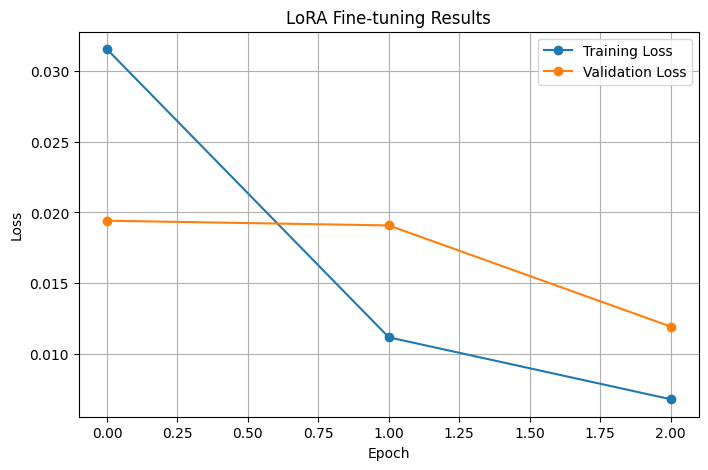

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(train_losses, marker="o", label="Training Loss")
plt.plot(val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LoRA Fine-tuning Results")

plt.legend()
plt.grid()
plt.show()


In [ ]:

from google.colab import drive
import os
import json

drive.mount("/content/drive")

save_path = "/content/drive/MyDrive/tndrr_ai_ml/Task1"

os.makedirs(save_path, exist_ok=True)

model.save_pretrained(save_path + "/best_lora")
tokenizer.save_pretrained(save_path + "/best_lora")

results = {
    "epochs": 3,
    "train_loss": train_losses,
    "validation_loss": val_losses,
    "lora_rank": 8,
    "lora_alpha": 16,
    "learning_rate": 0.0002,
    "gpu": torch.cuda.get_device_name(0)
}

with open(save_path + "/training_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model backup saved successfully!")


Mounted at /content/drive
Model backup saved successfully!


In [ ]:

import json
import re
from tqdm.auto import tqdm

categories = [
    "card_services",
    "payments_transfers",
    "cash_withdrawals",
    "account_security",
    "topups_balances",
    "fees_refunds_exchange"
]

tokenizer.padding_side = "left"

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


def get_predictions(data, use_lora=True, batch_size=16):

    model.eval()
    predictions = []
    valid_json = 0

    prompts = []

    for item in data:
        messages = [
            {
                "role": "system",
                "content": item["instruction"]
            },
            {
                "role": "user",
                "content": item["input"]
            }
        ]

        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        prompts.append(prompt)

    if use_lora:
        context = model.disable_adapter if False else None
    else:
        context = model.disable_adapter()

    from contextlib import nullcontext

    if use_lora:
        context = nullcontext()

    with context:

        with torch.inference_mode():

            for i in tqdm(range(0, len(prompts), batch_size)):

                batch_prompts = prompts[i:i + batch_size]

                inputs = tokenizer(
                    batch_prompts,
                    padding=True,
                    truncation=True,
                    max_length=512,
                    return_tensors="pt"
                ).to(model.device)

                outputs = model.generate(
                    **inputs,
                    max_new_tokens=40,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id
                )

                new_tokens = outputs[:, inputs["input_ids"].shape[1]:]

                responses = tokenizer.batch_decode(
                    new_tokens,
                    skip_special_tokens=True
                )

                for response in responses:

                    category = "__invalid__"

                    match = re.search(r"\{.*?\}", response, re.DOTALL)

                    if match:
                        try:
                            result = json.loads(match.group())

                            if (
                                isinstance(result, dict)
                                and result.get("category") in categories
                            ):
                                category = result["category"]
                                valid_json += 1

                        except (json.JSONDecodeError, TypeError):
                            pass

                    predictions.append(category)

    return predictions, valid_json


In [ ]:

base_predictions, base_valid = get_predictions(
    test_list,
    use_lora=False
)

print("Base model evaluation completed!")
print("Total predictions:", len(base_predictions))
print("Valid JSON responses:", base_valid)


  0%|          | 0/193 [00:00<?, ?it/s]

Base model evaluation completed!
Total predictions: 3080
Valid JSON responses: 2001


In [ ]:

lora_predictions, lora_valid = get_predictions(
    test_list,
    use_lora=True
)

print("Fine-tuned model evaluation completed!")
print("Total predictions:", len(lora_predictions))
print("Valid JSON responses:", lora_valid)


  0%|          | 0/193 [00:00<?, ?it/s]

Fine-tuned model evaluation completed!
Total predictions: 3080
Valid JSON responses: 3076


In [ ]:

from sklearn.metrics import accuracy_score, f1_score

y_true = list(y_test)

print("BASE MODEL")
print("Accuracy:", accuracy_score(y_true, base_predictions))
print("Macro F1:", f1_score(
    y_true, base_predictions,
    labels=categories,
    average="macro",
    zero_division=0
))
print("Valid JSON rate:", base_valid / len(y_true))


print("\nFINE-TUNED MODEL")
print("Accuracy:", accuracy_score(y_true, lora_predictions))
print("Macro F1:", f1_score(
    y_true, lora_predictions,
    labels=categories,
    average="macro",
    zero_division=0
))
print("Valid JSON rate:", lora_valid / len(y_true))


BASE MODEL
Accuracy: 0.24642857142857144
Macro F1: 0.2910359287131414
Valid JSON rate: 0.6496753246753246

FINE-TUNED MODEL
Accuracy: 0.9444805194805195
Macro F1: 0.9450693802779978
Valid JSON rate: 0.9987012987012988


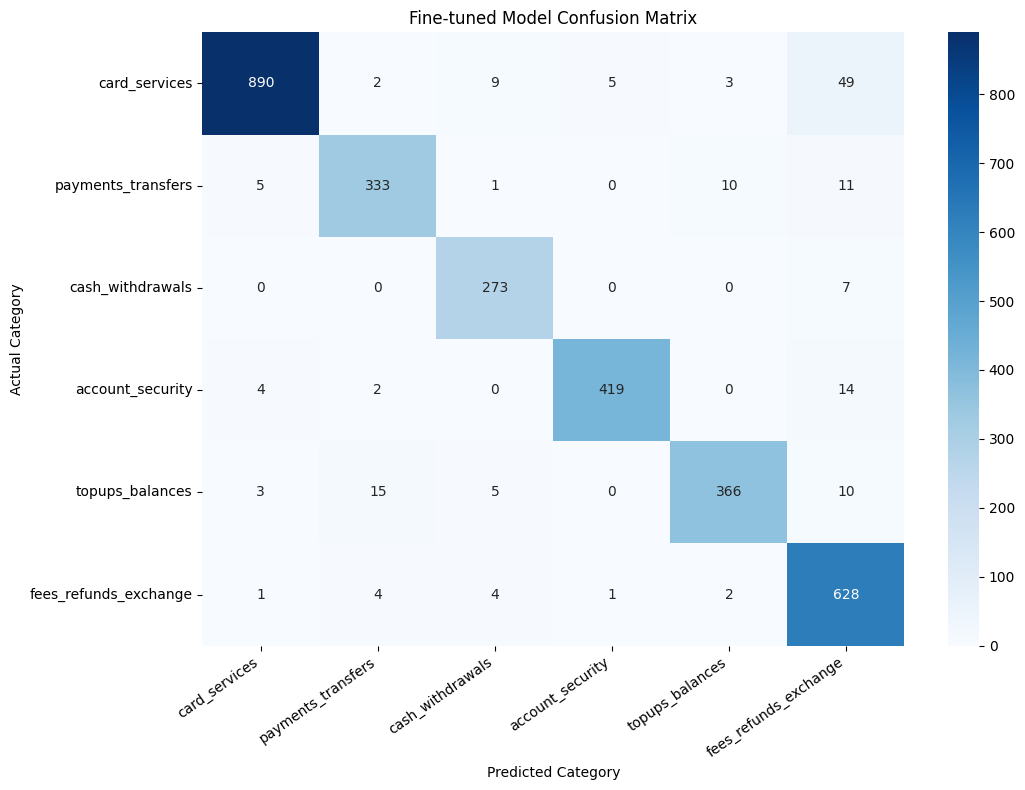

In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    lora_predictions,
    labels=categories
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=categories,
    yticklabels=categories
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Fine-tuned Model Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "task1_results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

report = classification_report(
    y_true,
    lora_predictions,
    labels=categories,
    target_names=categories,
    zero_division=0
)

print(report)

with open("task1_results/classification_report.txt", "w") as f:
    f.write(report)


                       precision    recall  f1-score   support

        card_services       0.99      0.93      0.96       960
   payments_transfers       0.94      0.93      0.93       360
     cash_withdrawals       0.93      0.97      0.95       280
     account_security       0.99      0.95      0.97       440
      topups_balances       0.96      0.92      0.94       400
fees_refunds_exchange       0.87      0.98      0.92       640

            micro avg       0.95      0.94      0.95      3080
            macro avg       0.95      0.95      0.95      3080
         weighted avg       0.95      0.94      0.95      3080



In [ ]:

results = pd.DataFrame({
    "text": list(x_test),
    "actual": list(y_test),
    "predicted": lora_predictions,
    "original_intent": test_data["intent"].tolist()
})

print("Columns:", results.columns.tolist())
print("Total examples:", len(results))
print(results.head(3))


Columns: ['text', 'actual', 'predicted', 'original_intent']
Total examples: 3080
                                                text         actual  \
0                           How do I locate my card?  card_services   
1  I still have not received my new card, I order...  card_services   
2  I ordered a card but it has not arrived. Help ...  card_services   

       predicted original_intent  
0  card_services    card_arrival  
1  card_services    card_arrival  
2  card_services    card_arrival  


In [ ]:

wrong = results[
    results["actual"] != results["predicted"]
].copy()

print("Total incorrect predictions:", len(wrong))

for i, row in wrong.head(3).iterrows():

    print("\nCustomer message:")
    print(row["text"])

    print("Original intent:", row["original_intent"])
    print("Actual category:", row["actual"])
    print("Predicted category:", row["predicted"])

    print("-" * 60)


Total incorrect predictions: 171

Customer message:
I've been waiting longer than expected for my card.
Original intent: card_arrival
Actual category: card_services
Predicted category: fees_refunds_exchange
------------------------------------------------------------

Customer message:
Why am I unable to take money from my card but the statement says the transaction is still pending?
Original intent: pending_cash_withdrawal
Actual category: cash_withdrawals
Predicted category: fees_refunds_exchange
------------------------------------------------------------

Customer message:
I tried to take money from my card, but it didn't work. Later I saw that the transaction is still in progress. What's goign on?
Original intent: pending_cash_withdrawal
Actual category: cash_withdrawals
Predicted category: fees_refunds_exchange
------------------------------------------------------------


In [ ]:

train_texts = set(x_train)
test_texts = set(x_test)

overlap = train_texts.intersection(test_texts)

print("Training unique messages:", len(train_texts))
print("Testing unique messages:", len(test_texts))
print("Exact overlapping messages:", len(overlap))


Training unique messages: 9002
Testing unique messages: 3080
Exact overlapping messages: 0
